# Анализ воронки продаж (E-commerce)

**Цель теста:** Построить воронку продаж, найти узкое горлышко (шаг с самым большим оттоком пользователей) и дать рекомендации по улучшению конверсии.

**Данные:** Данные взяты из открытого датасета Kaggle (E-commerce User Events). Ожидаемый результат — выявление этапа, на котором теряется больше всего клиентов.

In [4]:
# 1. Загрузка и первичная разведка данных (Data Profiling)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('user_events_ecommerce_product_analytics.csv')

print(df.head())
print()
df.info()

print("\n=== Уникальные типы событий ===")
print(df['event_type'].value_counts())

print(f"\nВсего уникальных пользователей: {df['user_id'].nunique()}")

   user_id session_id  event_date event_time   event_type product_id  \
0  U110476   S2867825  2024-01-13   09:23:00         view      P3286   
1  U100520   S1499914  2024-02-17   07:27:00     purchase      P4257   
2  U100106   S3678638  2024-12-23   14:25:00  add_to_cart      P3547   
3  U101519   S7374122  2024-02-19   12:15:00         view      P1711   
4  U101291   S5918715  2024-11-17   21:06:00        visit      P2139   

      category    price  device traffic_source country           city  
0    Men Pants      NaN  Mobile       Referral     USA  San Francisco  
1  Casual Wear  2502.94     Web          Email     USA       New York  
2  Women Pants  4815.02     Web        Organic      UK     Manchester  
3  Formal Wear      NaN  Mobile       Referral      UK     Manchester  
4    Men Pants      NaN  Mobile          Email      UK         London  

<class 'pandas.DataFrame'>
RangeIndex: 320000 entries, 0 to 319999
Data columns (total 12 columns):
 #   Column          Non-Null Coun

**Вывод по этапу разведки:**
Данные содержат 320 000 событий и 12 000 уникальных пользователей. В датасете представлена классическая воронка e-commerce с пятью этапами: `visit`, `view`, `add_to_cart`, `checkout`, `purchase`. 
Выявлено большое количество пропусков в столбце `price` (около 40%). Это логично: цена фиксируется только на этапах взаимодействия с товаром (корзина, покупка), а на этапе простого визита (`visit`) её нет. Для анализа воронки этот пропуск не критичен, поэтому заполнять его не будем.

In [10]:
# Формируем этапы воронки
funnel_steps = ['visit', 'view', 'add_to_cart', 'checkout', 'purchase']

# Считаем уникальных пользователей на каждом этапе
funnel_counts = df.groupby('event_type')['user_id'].nunique()

# Собираем данные в таблицу
funnel = pd.DataFrame({'stage': funnel_steps})
funnel['users'] = funnel['stage'].map(funnel_counts)

# Рассчитываем общую конверсию и конверсию между шагами (в %)
funnel['overall_conversion'] = (funnel['users'] / funnel['users'].iloc[0]) * 100
funnel['step_conversion'] = (funnel['users'] / funnel['users'].shift(1)) * 100

print(funnel)

         stage  users  overall_conversion  step_conversion
0        visit  11995          100.000000              NaN
1         view  11998          100.025010       100.025010
2  add_to_cart  11888           99.107962        99.083181
3     checkout  11533           96.148395        97.013795
4     purchase  10566           88.086703        91.615365


**Вывод по построению воронки:**
При первичном расчете была выявлена аномалия: на этапе `view` пользователей оказалось больше (11 998), чем на этапе `visit` (11 995). Это означает, что часть пользователей попала сразу на страницу товара, минуя главную страницу, и трекер `visit` не сработал.

Чтобы воронка отражала реальный путь клиента, мы применили метод кумулятивного пересчета (снизу вверх): если пользователь дошел до следующего этапа, мы считаем, что он прошел и все предыдущие. Это позволяет избежать разрывов и корректно оценить сквозную конверсию.

Так как в дальнейшем потребуется строить воронки для разных сегментов (по устройствам, странам и т.д.), мы инкапсулировали логику расчета в функцию build_funnel() для избежания дублирования кода.

In [14]:
def build_funnel(data):
    """Строит воронку продаж с кумулятивным пересчетом (исправление аномалий)."""
    steps = ['visit', 'view', 'add_to_cart', 'checkout', 'purchase']
    
    # Считаем уникальных пользователей
    counts = data.groupby('event_type')['user_id'].nunique()
    
    # Кумулятивный пересчет снизу вверх (каждый шаг >= предыдущего)
    for i in range(len(steps)-2, -1, -1):
        counts[steps[i]] = max(counts[steps[i]], counts[steps[i+1]])
    
    # Формируем итоговую таблицу
    funnel = pd.DataFrame({'stage': steps})
    funnel['users'] = funnel['stage'].map(counts)
    funnel['overall_conversion'] = (funnel['users'] / funnel['users'].iloc[0]) * 100
    funnel['step_conversion'] = (funnel['users'] / funnel['users'].shift(1)) * 100
    
    return funnel

In [15]:
# Строим общую воронку через функцию
funnel_total = build_funnel(df)
print(funnel_total)

         stage  users  overall_conversion  step_conversion
0        visit  11998          100.000000              NaN
1         view  11998          100.000000       100.000000
2  add_to_cart  11888           99.083181        99.083181
3     checkout  11533           96.124354        97.013795
4     purchase  10566           88.064677        91.615365


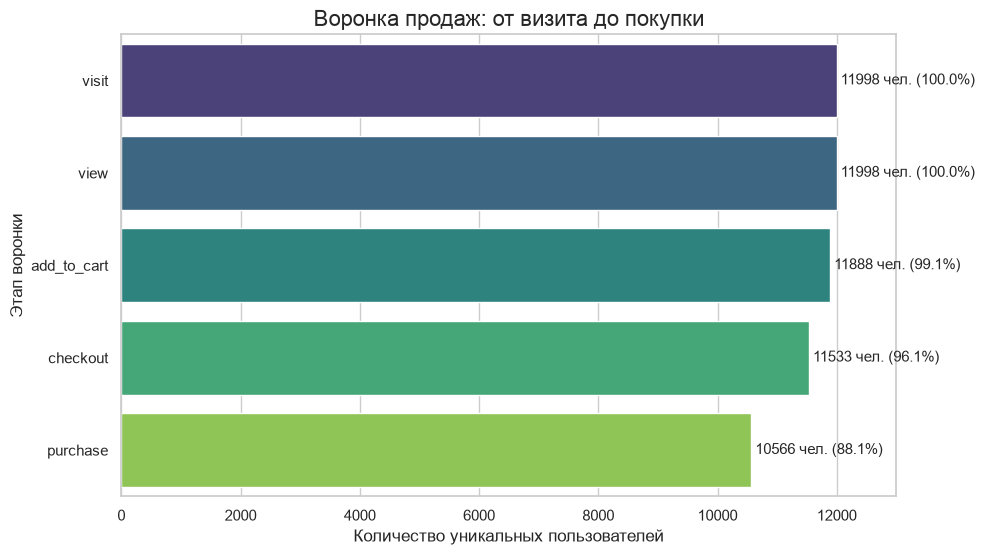

In [17]:
#График общей воронки
sns.set_theme(style="whitegrid", palette="muted")
plt.figure(figsize=(10, 6))

sns.barplot(x='users', y='stage', data=funnel_total, hue='stage', palette='viridis', legend=False)

# Добавляем текстовые подписи с количеством людей и процентом на каждый столбец
for index, value in enumerate(funnel['users']):
    plt.text(value, index, f' {value} чел. ({funnel_total["overall_conversion"][index]:.1f}%)', 
             va='center', fontsize=11)

plt.title('Воронка продаж: от визита до покупки', fontsize=16)
plt.xlabel('Количество уникальных пользователей', fontsize=12)
plt.ylabel('Этап воронки', fontsize=12)
plt.xlim(0, 13000) 
plt.show()

**Вывод по воронке:**
Сквозная конверсия из визита в покупку составляет 88.06%. Наибольший отток пользователей происходит на этапе `checkout -> purchase` (падение конверсии до 91.61%). Это означает, что около 8.4% пользователей, которые дошли до оформления заказа, бросают покупку на этапе оплаты. Именно этот этап является «узким горлышком» воронки.

Чтобы понять, оказывает ли платформа влияние на путь клиента, построим отдельные воронки для сегментов 'Mobile' и 'Web'.

In [18]:
# Фильтруем данные
df_mobile = df[df['device'] == 'Mobile']
df_web = df[df['device'] == 'Web']

# Строим воронки для разных устройств
funnel_mobile = build_funnel(df_mobile)
funnel_web = build_funnel(df_web)

print("=== Воронка: Mobile ===")
print(funnel_mobile)
print("\n=== Воронка: Web ===")
print(funnel_web)

=== Воронка: Mobile ===
         stage  users  overall_conversion  step_conversion
0        visit  11836          100.000000              NaN
1         view  11836          100.000000       100.000000
2  add_to_cart  10948           92.497465        92.497465
3     checkout   9675           81.742143        88.372305
4     purchase   7872           66.508956        81.364341

=== Воронка: Web ===
         stage  users  overall_conversion  step_conversion
0        visit  11820          100.000000              NaN
1         view  11820          100.000000       100.000000
2  add_to_cart  10863           91.903553        91.903553
3     checkout   9562           80.896785        88.023566
4     purchase   7838           66.311337        81.970299


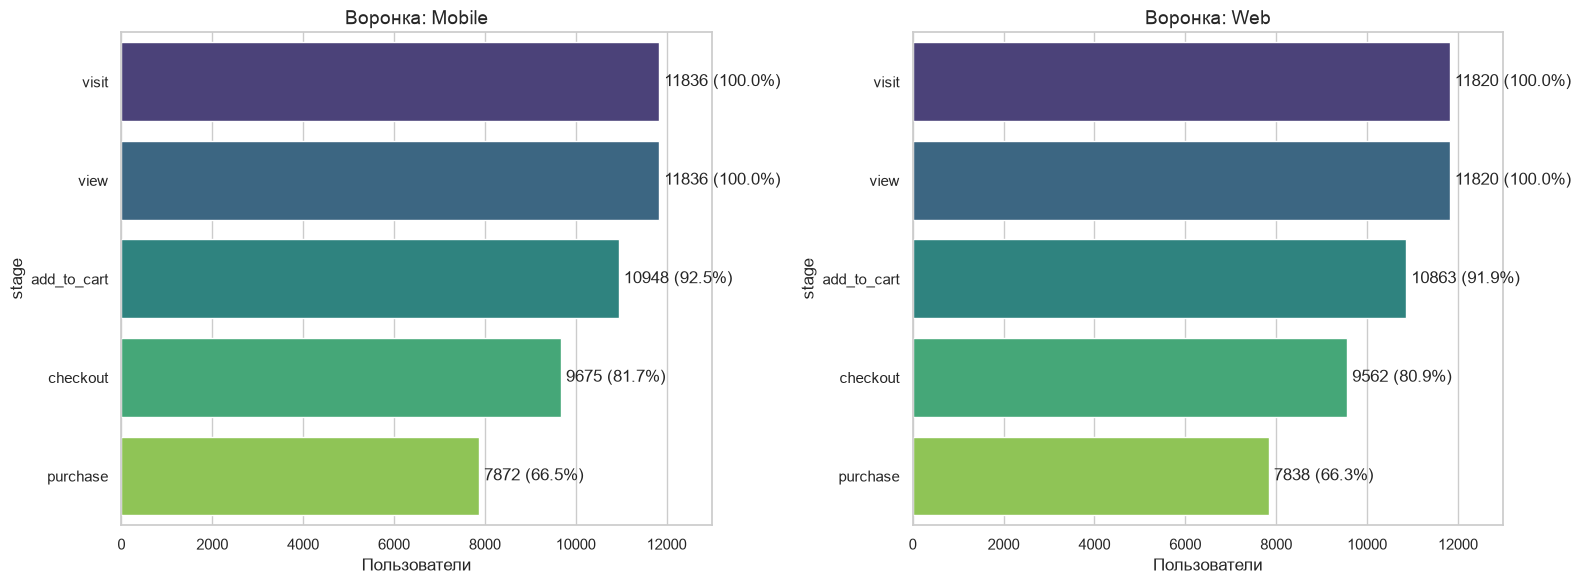

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# График для Mobile
sns.barplot(x='users', y='stage', data=funnel_mobile, hue='stage', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Воронка: Mobile', fontsize=14)
axes[0].set_xlabel('Пользователи')
axes[0].set_xlim(0, 13000)
for index, value in enumerate(funnel_mobile['users']):
    axes[0].text(value, index, f' {value} ({funnel_mobile["overall_conversion"][index]:.1f}%)', va='center')

# График для Web
sns.barplot(x='users', y='stage', data=funnel_web, hue='stage', palette='viridis', legend=False, ax=axes[1])
axes[1].set_title('Воронка: Web', fontsize=14)
axes[1].set_xlabel('Пользователи')
axes[1].set_xlim(0, 13000)
for index, value in enumerate(funnel_web['users']):
    axes[1].text(value, index, f' {value} ({funnel_web["overall_conversion"][index]:.1f}%)', va='center')

plt.tight_layout()
plt.show()

**Вывод по устройствам:**
Сквозная конверсия на мобильных устройствах (66.5%) и на компьютерах (66.3%) практически идентична. Самое сильное падение на обоих платформах происходит на последнем шаге (`checkout -> purchase`). Это означает, что проблема с бросанием покупки на этапе оплаты не связана с типом устройства.

Проверим, связана ли проблема с тем, откуда пользователи пришли на сайт ('traffic_source').

In [21]:
# Считаем уникальных пользователей и купивших для каждого источника
source_stats = df.groupby('traffic_source').agg(
    total_users=('user_id', 'nunique'),
    buyers=('user_id', lambda x: df[df['user_id'].isin(x) & (df['event_type'] == 'purchase')]['user_id'].nunique())
)

# Считаем конверсию
source_stats['conversion'] = (source_stats['buyers'] / source_stats['total_users']) * 100

# Сортируем по убыванию конверсии
source_stats = source_stats.sort_values('conversion', ascending=False)
print(source_stats)

                total_users  buyers  conversion
traffic_source                                 
Organic               11979   10550   88.070791
Ads                   11984   10554   88.067423
Email                 11984   10554   88.067423
Referral              11986   10555   88.061071


**Вывод по источнику трафика:**
Анализ показал, что конверсия из визита в покупку практически идентична для всех источников (около 88%). Источник трафика не является причиной отвала пользователей на этапе оплаты, поэтому гипотезу отклоняем.

Перейдём к анализу по странам.

In [22]:
# Считаем уникальных пользователей, дошедших до checkout и до purchase, по каждой стране
country_stats = df[df['event_type'].isin(['checkout', 'purchase'])].groupby(['country', 'event_type'])['user_id'].nunique().unstack()

# Считаем конверсию шага checkout -> purchase
country_stats['conversion'] = (country_stats['purchase'] / country_stats['checkout']) * 100

# Сортируем по конверсии (от самой низкой к самой высокой)
country_stats = country_stats.sort_values('conversion', ascending=True)
print(country_stats)

event_type  checkout  purchase  conversion
country                                   
USA             5712      4108   71.918768
UK              5659      4096   72.380279
Germany         5655      4107   72.625995
India           5778      4237   73.329872
Australia       5685      4242   74.617414


**Вывод по странам:**
Конверсия из `checkout` в `purchase` во всех странах находится примерно на одном уровне (от 71.9% до 74.6%). Аномалий нет. Страна пользователя не является причиной отвала на этапе оплаты. Гипотезу отклоняем.

Возможно, на итоговое решение пользователей оказывает влияние цена товара.

In [23]:
# Средняя цена на этапе checkout
checkout_price = df[df['event_type'] == 'checkout']['price'].mean()

# Средняя цена на этапе purchase
purchase_price = df[df['event_type'] == 'purchase']['price'].mean()

print(f"Средняя цена товаров, которые дошли до оплаты: {checkout_price:.2f}")
print(f"Средняя цена товаров, которые купили: {purchase_price:.2f}")

Средняя цена товаров, которые дошли до оплаты: 2851.37
Средняя цена товаров, которые купили: 2843.78


**Вывод по средней цене:**
Разница в средней цене минимальна, однако средняя цена может скрывать проблему: возможно, отвал происходит не из-за стоимости, а из-за конкретной категории товаров или даже одного «сломанного» товара. Проверим конверсию `checkout -> purchase` в разрезе категорий и `product_id`.

In [24]:
# Считаем конверсию для категорий
cat_stats = df[df['event_type'].isin(['checkout', 'purchase'])].groupby(['category', 'event_type'])['user_id'].nunique().unstack()
cat_stats['conversion'] = (cat_stats['purchase'] / cat_stats['checkout']) * 100
cat_stats = cat_stats.sort_values('conversion', ascending=True)
print("=== Конверсия по категориям ===")
print(cat_stats)

=== Конверсия по категориям ===
event_type   checkout  purchase  conversion
category                                   
Men Pants        5642      4077   72.261609
Casual Wear      5748      4155   72.286013
Formal Wear      5712      4130   72.303922
Jeans            5691      4193   73.677737
Women Pants      5704      4239   74.316269


In [25]:
# Считаем конверсию для конкретных товаров (product_id)
# Нас интересуют только те товары, где было хотя бы 10 попыток оформления (чтобы отсеять шум)
prod_stats = df[df['event_type'].isin(['checkout', 'purchase'])].groupby(['product_id', 'event_type'])['user_id'].nunique().unstack()
prod_stats = prod_stats[prod_stats['checkout'] >= 10] # Фильтр: хотя бы 10 чек-аутов
prod_stats['conversion'] = (prod_stats['purchase'] / prod_stats['checkout']) * 100
prod_stats = prod_stats.sort_values('conversion', ascending=True)

print("\n=== ТОП-5 ХУДШИХ ТОВАРОВ (по конверсии) ===")
print(prod_stats.head(5))


=== ТОП-5 ХУДШИХ ТОВАРОВ (по конверсии) ===
event_type  checkout  purchase  conversion
product_id                                
P3958           13.0       1.0    7.692308
P2361           12.0       1.0    8.333333
P5162           11.0       1.0    9.090909
P2623           11.0       1.0    9.090909
P6206           11.0       1.0    9.090909


**Вывод по товарам:**
Анализ показал, что в то время как средняя конверсия магазина составляет ~72%, существуют отдельные товары (например, P3958, P2361), конверсия которых критически низкая — около 7-9%. Пользователи активно пытаются оформить эти заказы (от 11 до 13 попыток), но не завершают покупку.

**Следующий шаг:** Необходимо оценить масштаб этой проблемы — сколько всего таких «проблемных» товаров в каталоге и какую долю от общего числа заказов они составляют. Если их много, это может быть главной причиной общего падения конверсии.

In [26]:
# Считаем, сколько всего товаров имеют конверсию ниже 30%
bad_products = prod_stats[prod_stats['conversion'] < 30]
print(f"Количество товаров с конверсией ниже 30%: {len(bad_products)}")

# Считаем, сколько всего попыток оплаты (checkout) пришлось на эти товары
total_checkouts = prod_stats['checkout'].sum()
bad_checkouts = bad_products['checkout'].sum()
print(f"Доля попыток оплаты 'плохих' товаров от всех: {(bad_checkouts / total_checkouts) * 100:.2f}%")

Количество товаров с конверсией ниже 30%: 60
Доля попыток оплаты 'плохих' товаров от всех: 55.42%


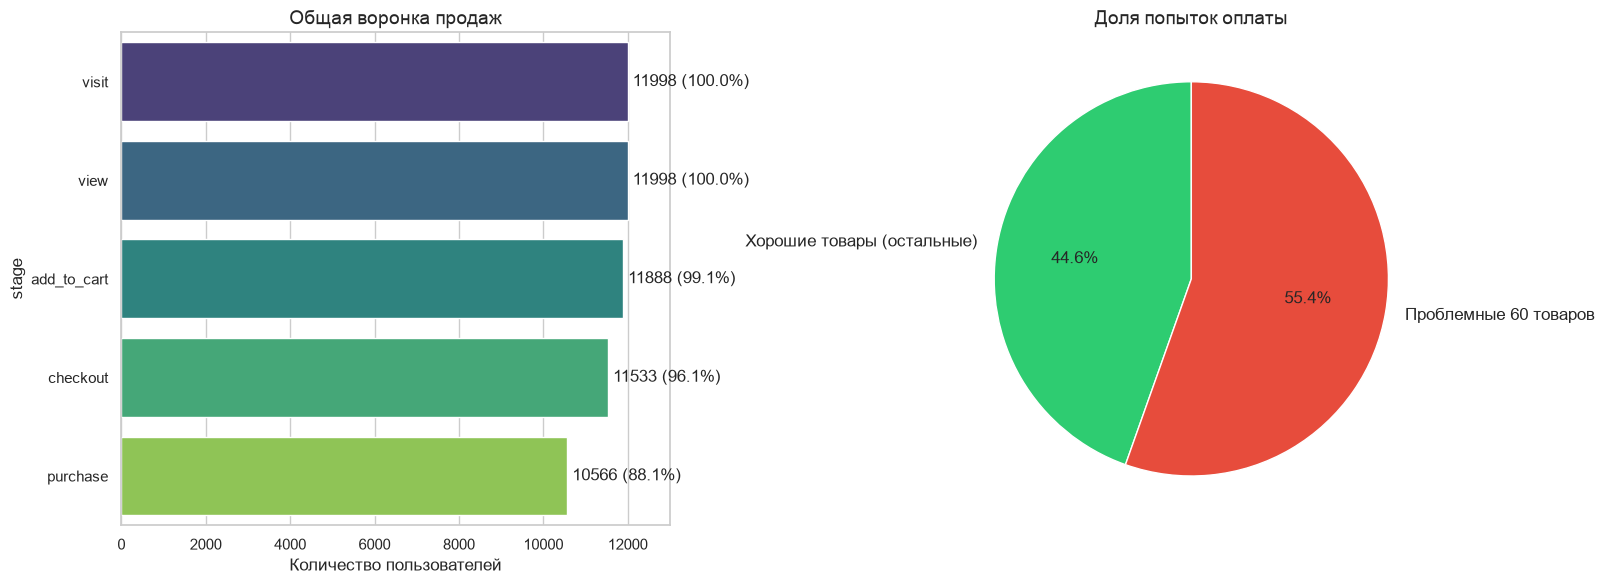

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. График слева: Воронка
sns.barplot(x='users', y='stage', data=funnel_total, hue='stage', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Общая воронка продаж', fontsize=14)
axes[0].set_xlabel('Количество пользователей')
axes[0].set_xlim(0, 13000)
for index, value in enumerate(funnel_total['users']):
    axes[0].text(value, index, f' {value} ({funnel_total["overall_conversion"][index]:.1f}%)', va='center')

# 2. График справа: Проблемные товары
# Подготовим данные для графика (сколько чекаутов у хороших, а сколько у плохих)
good_checkouts = total_checkouts - bad_checkouts
labels = ['Хорошие товары (остальные)', 'Проблемные 60 товаров']
sizes = [good_checkouts, bad_checkouts]
colors = ['#2ecc71', '#e74c3c'] # Зеленый и красный

axes[1].pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90, textprops={'fontsize': 12})
axes[1].set_title('Доля попыток оплаты', fontsize=14)

plt.tight_layout()
plt.savefig('funnel_and_products.png', dpi=300, bbox_inches='tight')
plt.show()

## Итоговые выводы и рекомендации

**Главный результат:**
В ходе анализа воронки продаж было выявлено, что основная потеря пользователей происходит на этапе `checkout -> purchase` (конверсия падает до 72%).

**Найденная причина:**
Детальный анализ на уровне товаров (`product_id`) показал, что **60 конкретных товаров** имеют аномально низкую конверсию (7-9% вместо средних 72%). При этом на эти 60 товаров приходится **55.42%** всех попыток оформления заказа! Это означает, что больше половины клиентов, готовых купить, отваливаются именно из-за проблем с этими конкретными позициями.

**Возможные технические причины:**
*   Ошибка на странице оплаты для этих товаров (не рассчитывается доставка, не принимается карта).
*   Отсутствие товара на складе (out of stock), но система не убрала его из продажи.
*   Ошибка в цене или весе товара.

**Рекомендации для бизнеса:**
1. Передать список из 60 `product_id` команде разработки для немедленного технического аудита.
2. Внедрить автоматический мониторинг конверсии по товарам (алерт, если конверсия конкретного товара падает ниже 30%).
3. После устранения технических ошибок ожидается значительный рост общей выручки за счет восстановления 55% «потерянных» заказов.